___

<a href='http://www.pieriandata.com'> <img src='../Pierian_Data_Logo.png' /></a>
___
# Logistic Regression Project - Solutions

In this project we will be working with a fake advertising data set, indicating whether or not a particular internet user clicked on an Advertisement on a company website. We will try to create a model that will predict whether or not they will click on an ad based off the features of that user.

This data set contains the following features:

* 'Daily Time Spent on Site': consumer time on site in minutes
* 'Age': cutomer age in years
* 'Area Income': Avg. Income of geographical area of consumer
* 'Daily Internet Usage': Avg. minutes a day consumer is on the internet
* 'Ad Topic Line': Headline of the advertisement
* 'City': City of consumer
* 'Male': Whether or not consumer was male
* 'Country': Country of consumer
* 'Timestamp': Time at which consumer clicked on Ad or closed window
* 'Clicked on Ad': 0 or 1 indicated clicking on Ad

## Import Libraries

**Import a few libraries you think you'll need (Or just import them as you go along!)**

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Get the Data
**Read in the advertising.csv file and set it to a data frame called ad_data.**

In [14]:
ad_data = pd.read_csv('advertising.csv')

**Check the head of ad_data**

In [17]:
ad_data.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [19]:
ad_data.size

10000

In [21]:
ad_data.shape

(1000, 10)

In [23]:
ad_data.columns

Index(['Daily Time Spent on Site', 'Age', 'Area Income',
       'Daily Internet Usage', 'Ad Topic Line', 'City', 'Male', 'Country',
       'Timestamp', 'Clicked on Ad'],
      dtype='object')

In [25]:
ad_data.dtypes

Daily Time Spent on Site    float64
Age                           int64
Area Income                 float64
Daily Internet Usage        float64
Ad Topic Line                object
City                         object
Male                          int64
Country                      object
Timestamp                    object
Clicked on Ad                 int64
dtype: object

** Use info and describe() on ad_data**

In [27]:
ad_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [29]:
ad_data.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


In [31]:
ad_data.describe(include=object)

,Ad Topic Line,City,Country,Timestamp
count,1000,1000,1000,1000
unique,1000,969,237,1000
top,Cloned 5thgeneration orchestration,Lisamouth,France,2016-03-27 00:53:11
freq,1,3,9,1


## Exploratory Data Analysis

Let's use seaborn to explore the data!

Try recreating the plots shown below!

** Create a histogram of the Age**

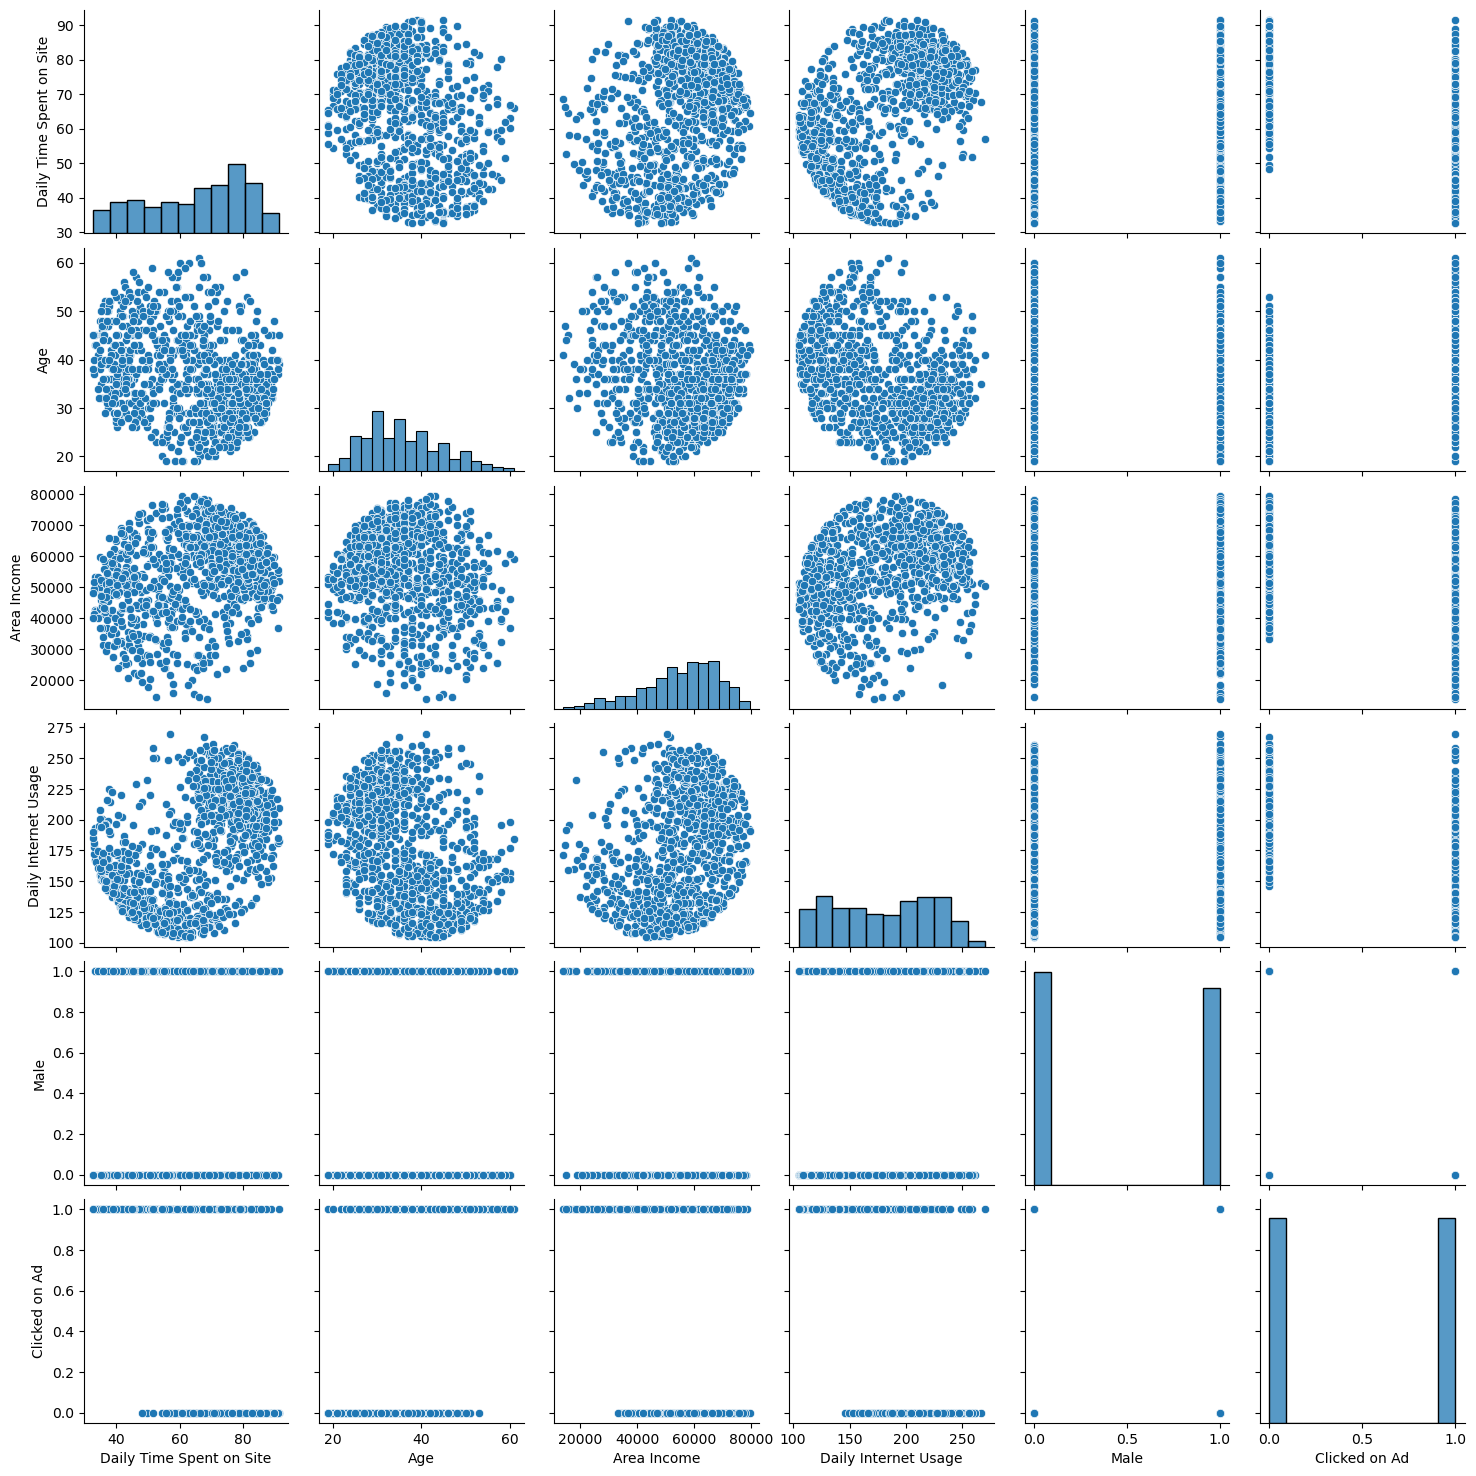

In [33]:
sns.pairplot(ad_data)
plt.show()

In [ ]:
ad_data.dtypes

**Distributions of Features**

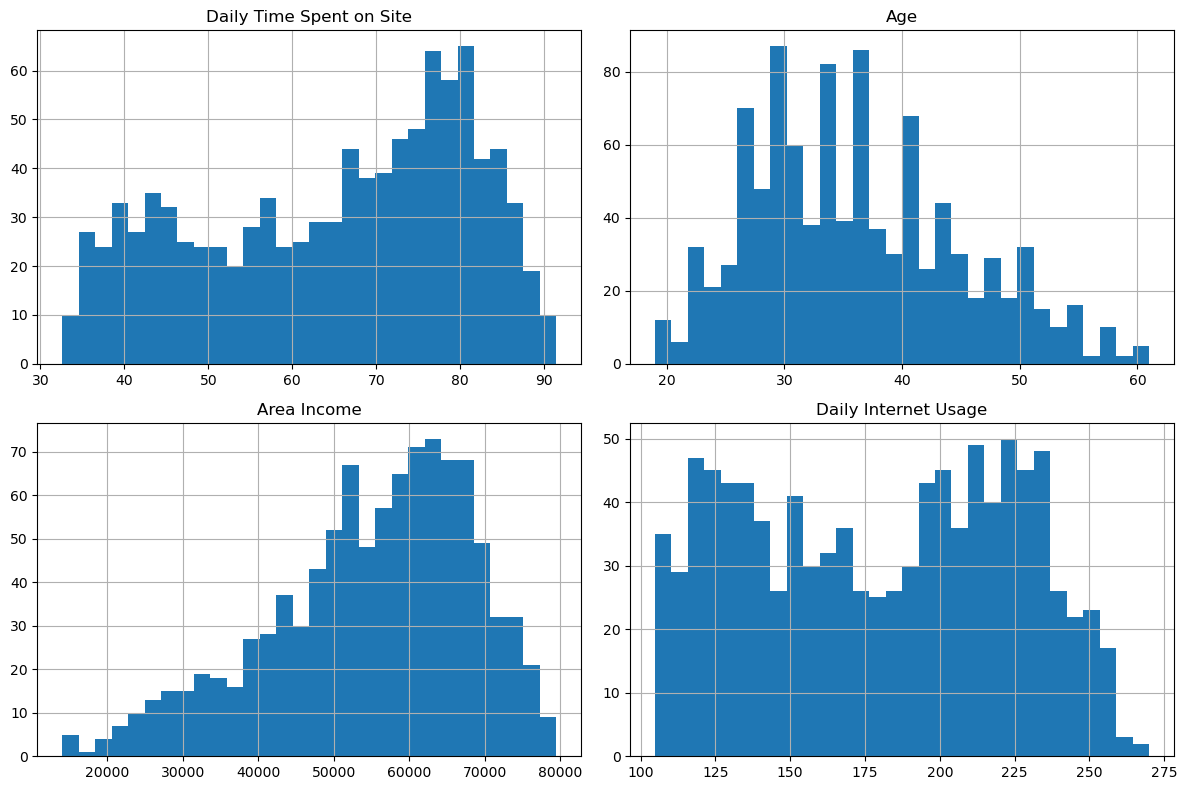

In [49]:
features = [ 'Daily Time Spent on Site' , 'Age' , 'Area Income' , 'Daily Internet Usage' ] 
ad_data[features].hist(figsize=(12,8) , bins = 30)
plt.tight_layout()
plt.show()

**Create a jointplot showing Area Income versus Age.**

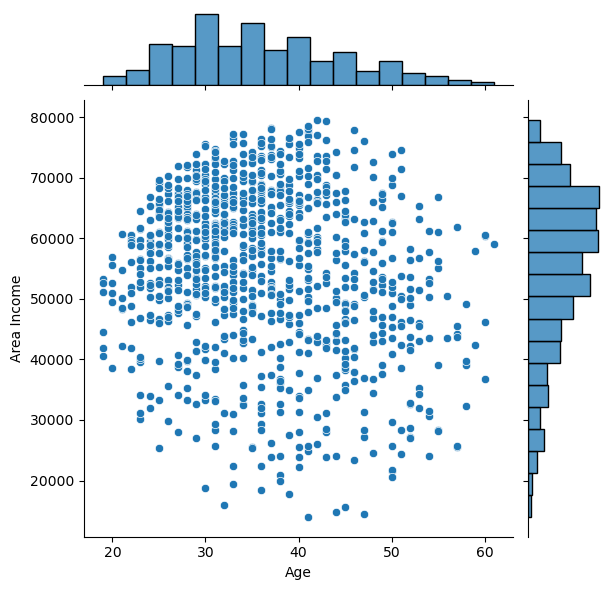

In [56]:
sns.jointplot(x='Age',y='Area Income',data=ad_data)
plt.show()

**Create a jointplot showing the kde distributions of Daily Time spent on site vs. Age.**

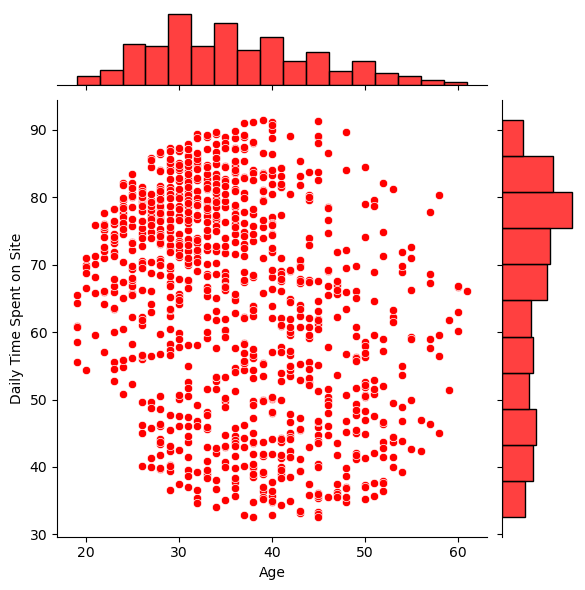

In [62]:
sns.jointplot(x='Age',y='Daily Time Spent on Site',data=ad_data,color='red');
plt.show()

** Create a jointplot of 'Daily Time Spent on Site' vs. 'Daily Internet Usage'**

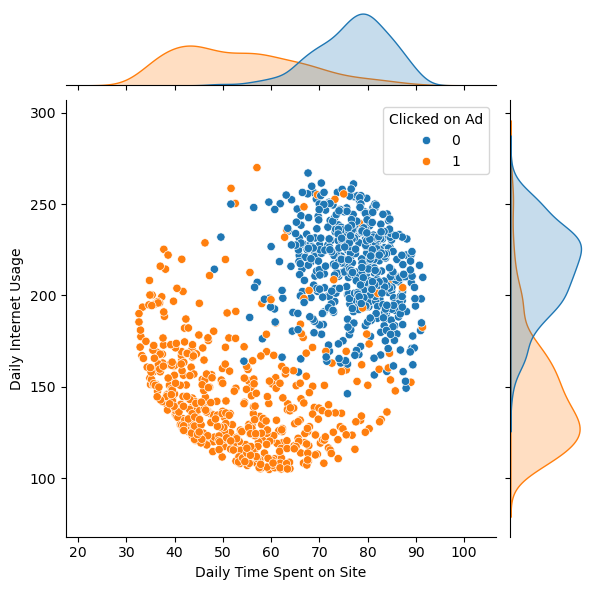

In [70]:
sns.jointplot(x='Daily Time Spent on Site',y='Daily Internet Usage',hue='Clicked on Ad',data=ad_data,color='green')
plt.show()

** Finally, create a pairplot with the hue defined by the 'Clicked on Ad' column feature.**

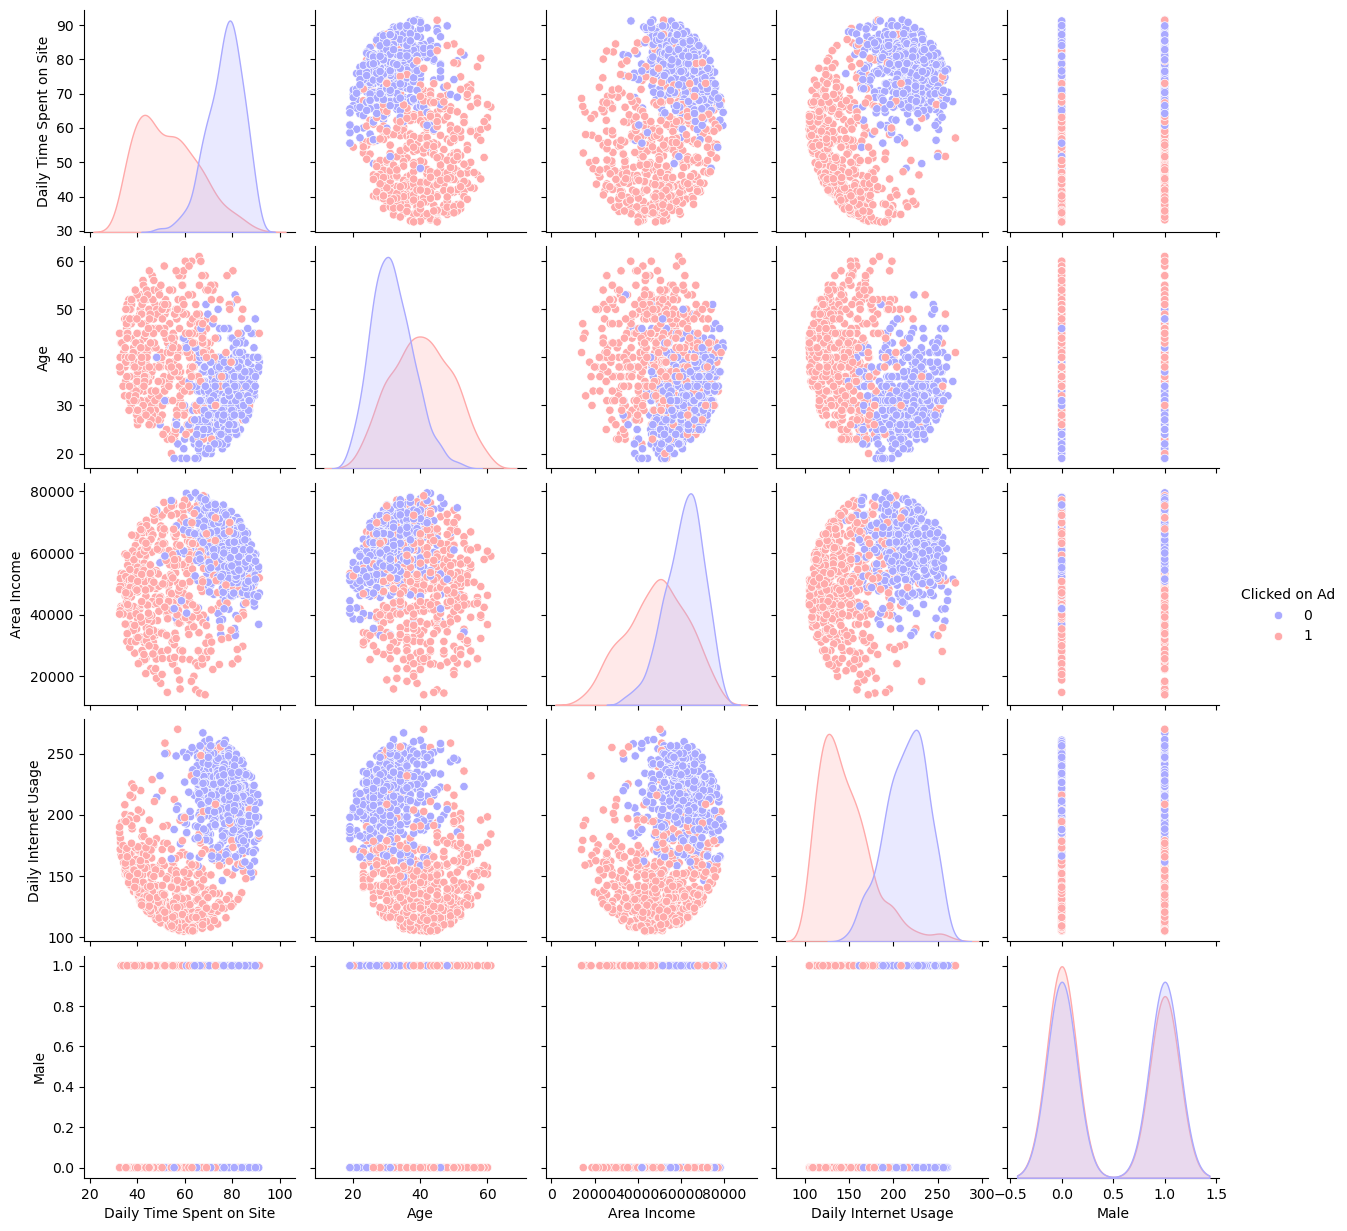

In [72]:
sns.pairplot(ad_data,hue='Clicked on Ad',palette='bwr')
plt.show()

# Logistic Regression

Now it's time to do a train test split, and train our model!

You'll have the freedom here to choose columns that you want to train on!

** Split the data into training set and testing set using train_test_split**

In [74]:
from sklearn.model_selection import train_test_split

In [78]:
X = ad_data[['Daily Time Spent on Site', 'Age', 'Area Income','Daily Internet Usage', 'Male']]
y = ad_data['Clicked on Ad']

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.36, random_state=42)

In [88]:
print(f"Training features - { X_train.shape } ")
print(f"Testing features - { X_test.shape } ")

Training features - (640, 5) 
Testing features - (360, 5) 


In [90]:
print(f"Testing Y - { y_test.shape } ")

Testing Y - (360,) 


** Train and fit a logistic regression model on the training set.**

In [92]:
from sklearn.linear_model import LogisticRegression

In [94]:
logmodel = LogisticRegression(max_iter=1000)

In [96]:
logmodel

LogisticRegression(max_iter=1000)

In [98]:
logmodel.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

## Predictions and Evaluations
** Now predict values for the testing data.**

In [100]:
predictions = logmodel.predict(X_test)

In [106]:
training_y = logmodel.predict(X_train)

In [108]:
print("Training Y" , y_train.shape)
print("Pred Training Y" , training_y.shape)

Training Y (640,)
Pred Training Y (640,)


In [104]:
print("Predicted Y" , predictions.shape)
print("Actual Y" , y_test.shape)

Predicted Y (360,)
Actual Y (360,)


In [ ]:
predictions

** Create a classification report for the model.**

## Training Evaluation of Model

In [112]:
from sklearn.metrics import (accuracy_score , precision_score , 
recall_score , f1_score , confusion_matrix , classification_report , 
roc_curve , roc_auc_score )

In [114]:
print(classification_report(y_train , training_y))

              precision    recall  f1-score   support

           0       0.97      0.98      0.98       321
           1       0.98      0.97      0.97       319

    accuracy                           0.97       640
   macro avg       0.98      0.97      0.97       640
weighted avg       0.98      0.97      0.97       640



In [116]:
cm = confusion_matrix(y_train , training_y , labels = [0,1])
print(cm)

[[315   6]
 [ 10 309]]


In [118]:
print(f" Accuracy score - { accuracy_score( y_train , training_y ) } ")
print(f" Recall score - { recall_score( y_train , training_y ) } ")
print(f" Precision score - { precision_score( y_train , training_y ) } ")
print(f" F1 score - { f1_score( y_train , training_y ) } ")
print(f" AUC ROC score - { roc_auc_score( y_train , training_y ) } ")

 Accuracy score - 0.975 
 Recall score - 0.9686520376175548 
 Precision score - 0.9809523809523809 
 F1 score - 0.9747634069400631 
 AUC ROC score - 0.9749802244162541 


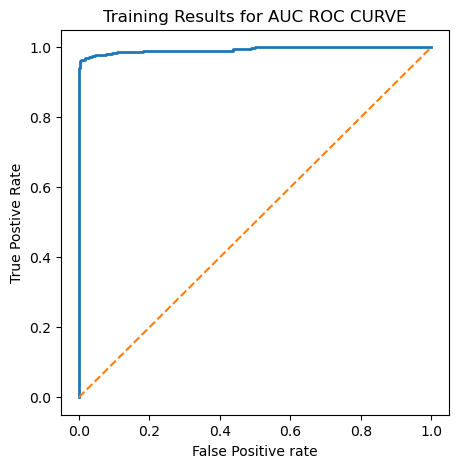

In [120]:
train_prob = logmodel.predict_proba(X_train)[:,1]
fpr , tpr , threshold = roc_curve(y_train, train_prob )
auc_score = roc_auc_score(y_train, train_prob)
plt.figure(figsize=(5,5))
plt.plot( fpr , tpr , label = f"Logistic regression ( Auc = {auc_score}",linewidth=2 )
plt.plot( [0,1] , [0,1] , linestyle = "--" , label = "random classifier")
plt.xlabel("False Positive rate")
plt.ylabel("True Postive Rate")
plt.title("Training Results for AUC ROC CURVE")
plt.show()

### Testing Evaluations 

In [123]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.96      0.97      0.96       179
           1       0.97      0.96      0.96       181

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



In [125]:
cm = confusion_matrix(y_test , predictions , labels = [0,1])
print(cm)

[[174   5]
 [  8 173]]


In [127]:
print(f" Accuracy score - { accuracy_score( y_test , predictions ) } ")
print(f" Recall score - { recall_score( y_test , predictions ) } ")
print(f" Precision score - { precision_score( y_test , predictions ) } ")
print(f" F1 score - { f1_score( y_test , predictions ) } ")
print(f" AUC ROC score - { roc_auc_score( y_test , predictions ) } ")

 Accuracy score - 0.9638888888888889 
 Recall score - 0.9558011049723757 
 Precision score - 0.9719101123595506 
 F1 score - 0.9637883008356546 
 AUC ROC score - 0.9639340720392605 


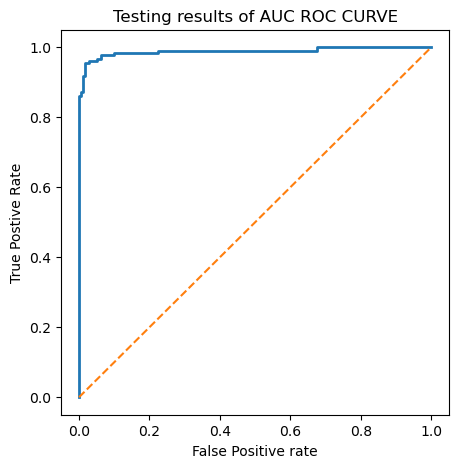

In [129]:
y_prob = logmodel.predict_proba(X_test)[:,1]
fpr , tpr , threshold = roc_curve(y_test, y_prob )
auc_score = roc_auc_score(y_test,y_prob)
plt.figure(figsize=(5,5))
plt.plot( fpr , tpr , label = f"Logistic regression ( Auc = {auc_score}",linewidth=2 )
plt.plot( [0,1] , [0,1] , linestyle = "--" , label = "random classifier")
plt.xlabel("False Positive rate")
plt.ylabel("True Postive Rate")
plt.title("Testing results of AUC ROC CURVE")
plt.show()

## Great Job!